
STEP 57 — CANCELLATION COUNT


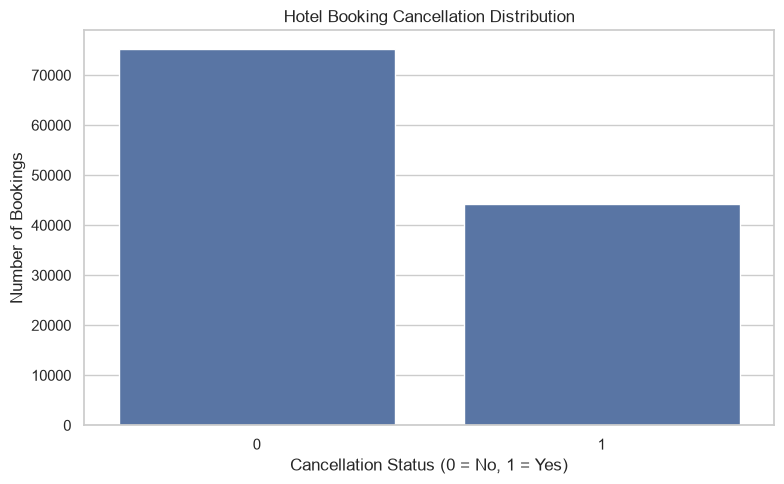

In [1]:
# ============================================================
# MEMBER 4 — VISUALIZATION & INTERPRETATION
# STEPS 57–70
# ============================================================

# Prerequisite: Run Member 2 first. This script loads the cleaned dataset.
# It also recomputes the target and correlation matrix needed for plots.

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

INPUT_FILE = (r"C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\preprocessing_results\hotel_bookings_cleaned.csv")
OUTPUT_FOLDER = 'output'
PREPROCESSING_FOLDER = os.path.join(OUTPUT_FOLDER, 'preprocessing_results')
EDA_FOLDER = os.path.join(OUTPUT_FOLDER, 'eda_results')
VISUALIZATION_FOLDER = os.path.join(OUTPUT_FOLDER, 'visualization_results')
ML_FOLDER = os.path.join(OUTPUT_FOLDER, 'machine_learning_results')
for folder in [OUTPUT_FOLDER, PREPROCESSING_FOLDER, EDA_FOLDER, VISUALIZATION_FOLDER, ML_FOLDER]:
    os.makedirs(folder, exist_ok=True)

CLEANED_FILE = os.path.join(PREPROCESSING_FOLDER, 'hotel_bookings_cleaned.csv')
if not os.path.exists(CLEANED_FILE):
    raise FileNotFoundError('Run Member 2 first; cleaned dataset not found: ' + CLEANED_FILE)
df = pd.read_csv(CLEANED_FILE)
target_column = 'is_canceled'
month_map = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6, 'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}
correlation_matrix = df.select_dtypes(include=np.number).corr()

# ============================================================
# STEP 57 — CANCELLATION COUNT VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 57 — CANCELLATION COUNT")
print("=" * 70)

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=target_column)

plt.title("Hotel Booking Cancellation Distribution")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_FOLDER, "step_57_cancellation_count.png"),
    dpi=300
)

plt.show()


STEP 58 — CANCELLATION BY HOTEL TYPE


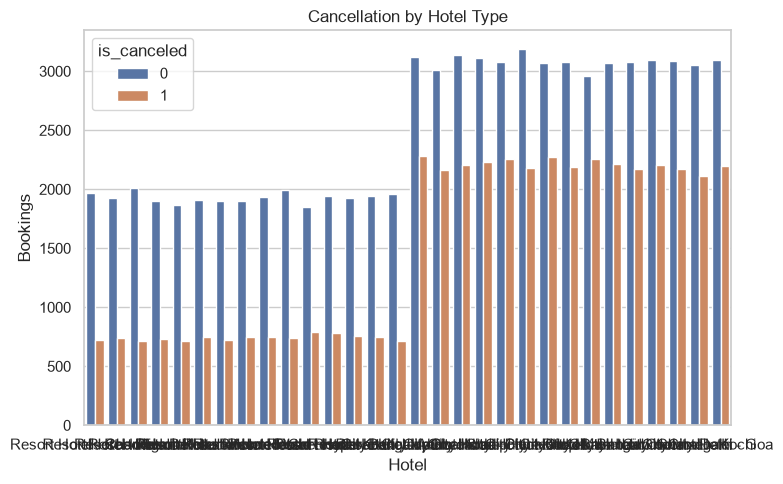

In [2]:
# ============================================================
# STEP 58 — CANCELLATION BY HOTEL TYPE
# ============================================================

print("\n" + "=" * 70)
print("STEP 58 — CANCELLATION BY HOTEL TYPE")
print("=" * 70)

if "hotel" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(data=df, x="hotel", hue=target_column)

    plt.title("Cancellation by Hotel Type")
    plt.xlabel("Hotel")
    plt.ylabel("Bookings")
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_58_hotel_type.png"),
        dpi=300
    )

    plt.show()


STEP 59 — LEAD TIME DISTRIBUTION


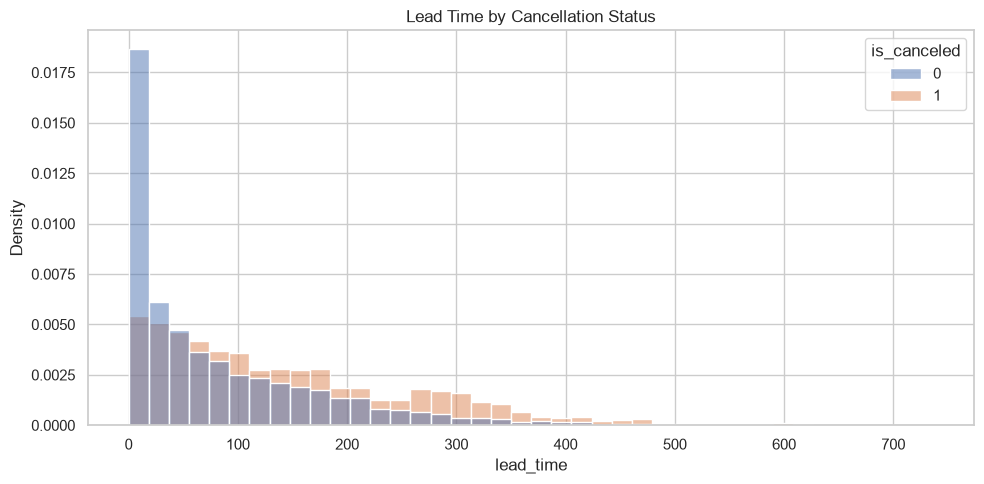

In [3]:
# ============================================================
# STEP 59 — LEAD TIME DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("STEP 59 — LEAD TIME DISTRIBUTION")
print("=" * 70)

if "lead_time" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x="lead_time",
        hue=target_column,
        bins=40,
        stat="density",
        common_norm=False
    )

    plt.title("Lead Time by Cancellation Status")
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_59_lead_time.png"),
        dpi=300
    )

    plt.show()


STEP 60 — ADR BOXPLOT


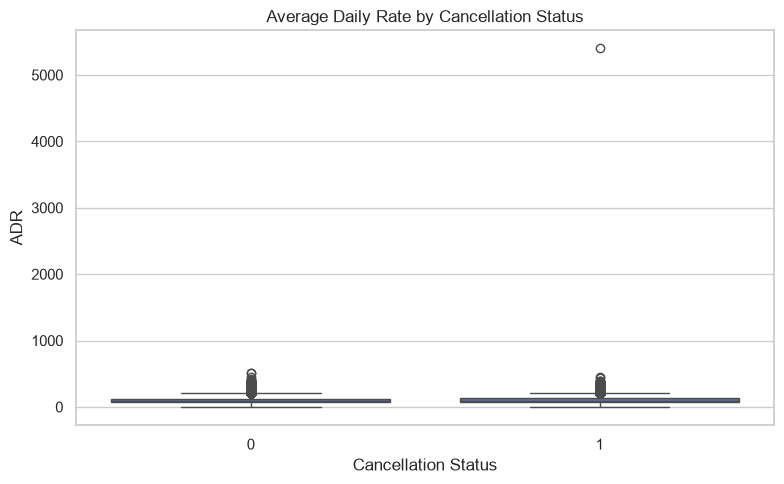

In [4]:
# ============================================================
# STEP 60 — ADR BOXPLOT
# ============================================================

print("\n" + "=" * 70)
print("STEP 60 — ADR BOXPLOT")
print("=" * 70)

if "adr" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df, x=target_column, y="adr")

    plt.title("Average Daily Rate by Cancellation Status")
    plt.xlabel("Cancellation Status")
    plt.ylabel("ADR")
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_60_adr_boxplot.png"),
        dpi=300
    )

    plt.show()


STEP 61 — MONTHLY CANCELLATION RATE


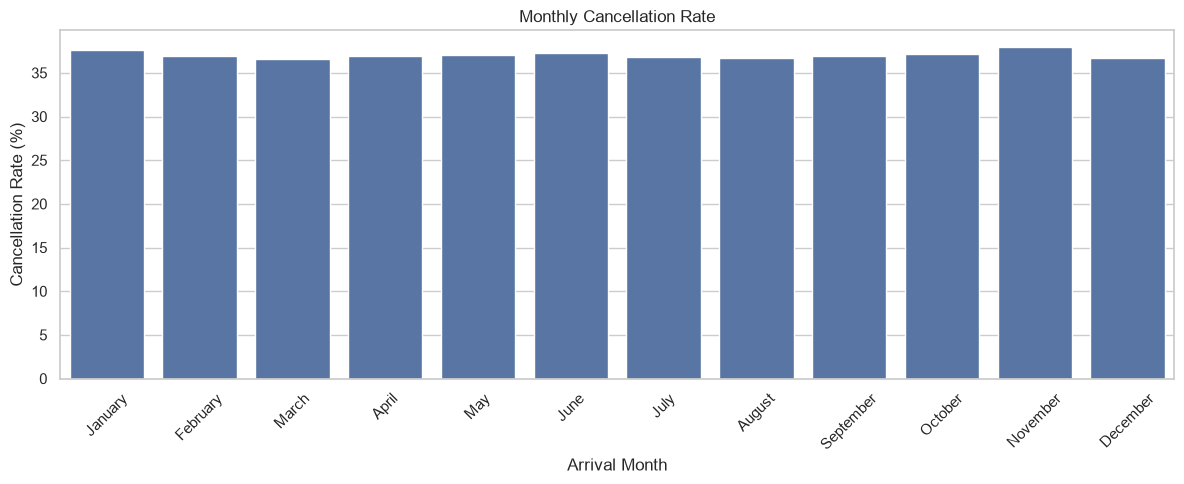

In [5]:
# ============================================================
# STEP 61 — MONTHLY CANCELLATION RATE
# ============================================================

print("\n" + "=" * 70)
print("STEP 61 — MONTHLY CANCELLATION RATE")
print("=" * 70)

if "arrival_date_month" in df.columns:

    month_order = list(month_map.keys())

    monthly_visual = (
        df.groupby("arrival_date_month")[target_column]
        .mean()
        .mul(100)
        .reindex(month_order)
    )

    plt.figure(figsize=(12, 5))

    sns.barplot(
        x=monthly_visual.index,
        y=monthly_visual.values
    )

    plt.title("Monthly Cancellation Rate")
    plt.xlabel("Arrival Month")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_61_monthly_rate.png"),
        dpi=300
    )

    plt.show()


STEP 62 — CUSTOMER TYPE VISUALIZATION


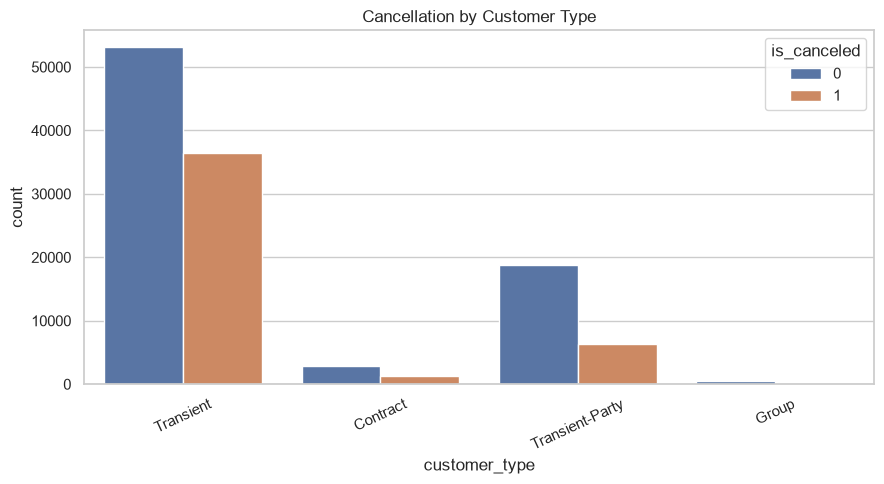

In [6]:
# ============================================================
# STEP 62 — CUSTOMER TYPE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 62 — CUSTOMER TYPE VISUALIZATION")
print("=" * 70)

if "customer_type" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="customer_type",
        hue=target_column
    )

    plt.title("Cancellation by Customer Type")
    plt.xticks(rotation=25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_62_customer_type.png"),
        dpi=300
    )

    plt.show()


STEP 63 — DEPOSIT TYPE VISUALIZATION


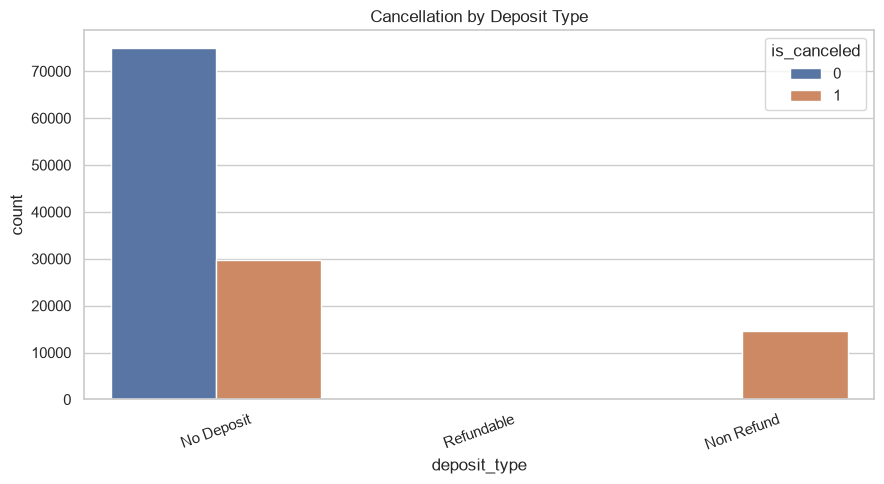

In [7]:
# ============================================================
# STEP 63 — DEPOSIT TYPE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 63 — DEPOSIT TYPE VISUALIZATION")
print("=" * 70)

if "deposit_type" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="deposit_type",
        hue=target_column
    )

    plt.title("Cancellation by Deposit Type")
    plt.xticks(rotation=20)
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_63_deposit_type.png"),
        dpi=300
    )

    plt.show()


STEP 64 — MARKET SEGMENT VISUALIZATION


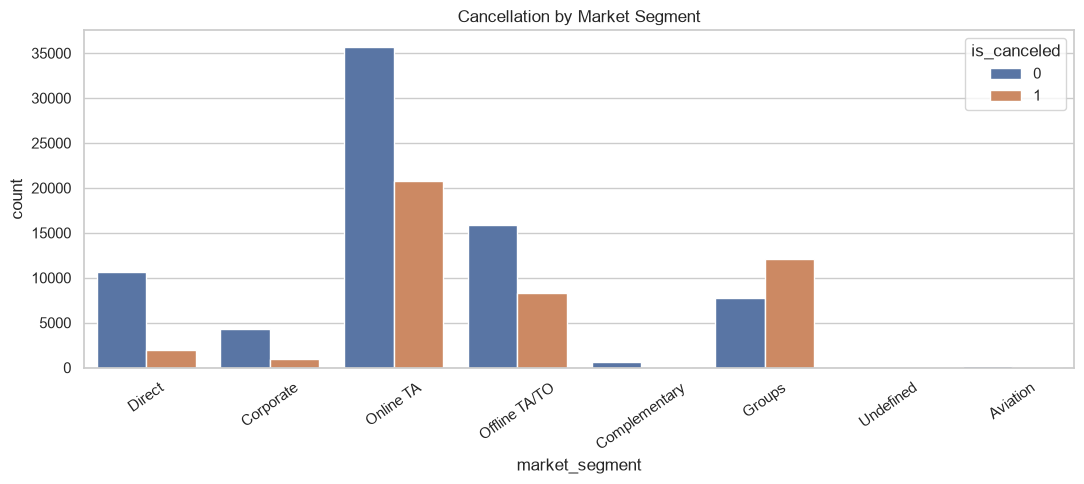

In [8]:
# ============================================================
# STEP 64 — MARKET SEGMENT VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 64 — MARKET SEGMENT VISUALIZATION")
print("=" * 70)

if "market_segment" in df.columns:

    plt.figure(figsize=(11, 5))

    sns.countplot(
        data=df,
        x="market_segment",
        hue=target_column
    )

    plt.title("Cancellation by Market Segment")
    plt.xticks(rotation=35)
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_64_market_segment.png"),
        dpi=300
    )

    plt.show()


STEP 65 — CORRELATION HEATMAP


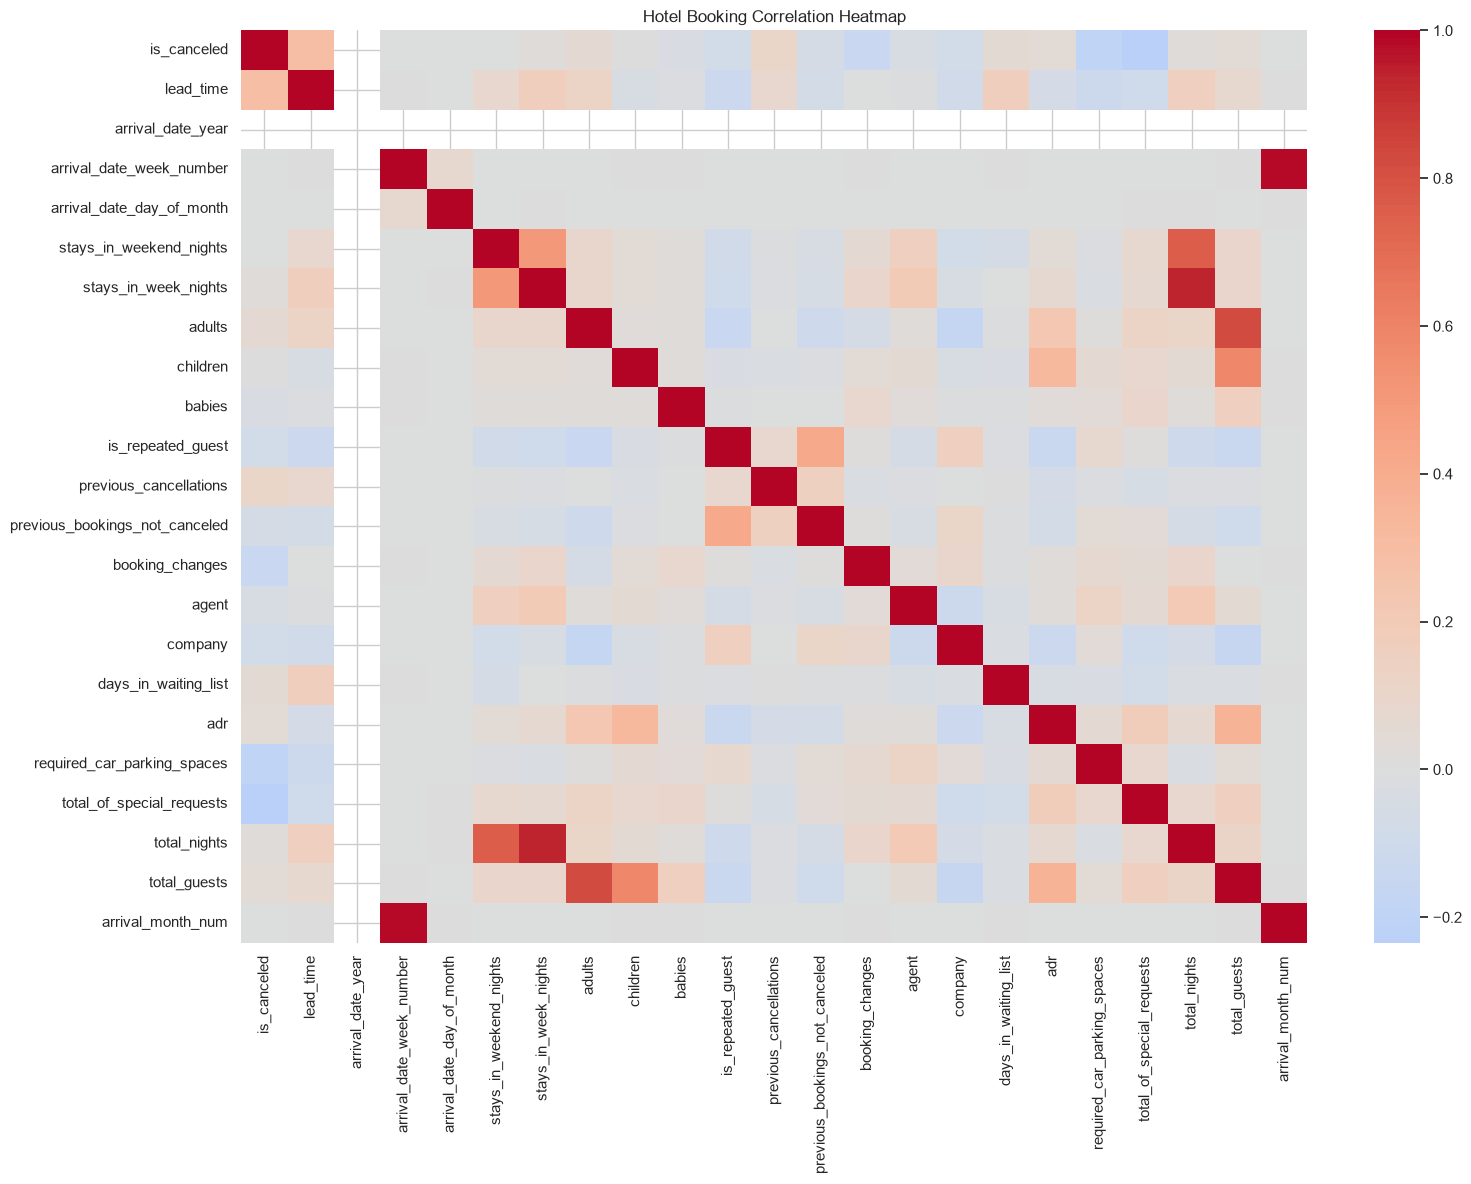

In [9]:
# ============================================================
# STEP 65 — CORRELATION HEATMAP
# ============================================================

print("\n" + "=" * 70)
print("STEP 65 — CORRELATION HEATMAP")
print("=" * 70)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Hotel Booking Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    os.path.join(VISUALIZATION_FOLDER, "step_65_correlation_heatmap.png"),
    dpi=300
)

plt.show()


STEP 66 — PREVIOUS CANCELLATIONS


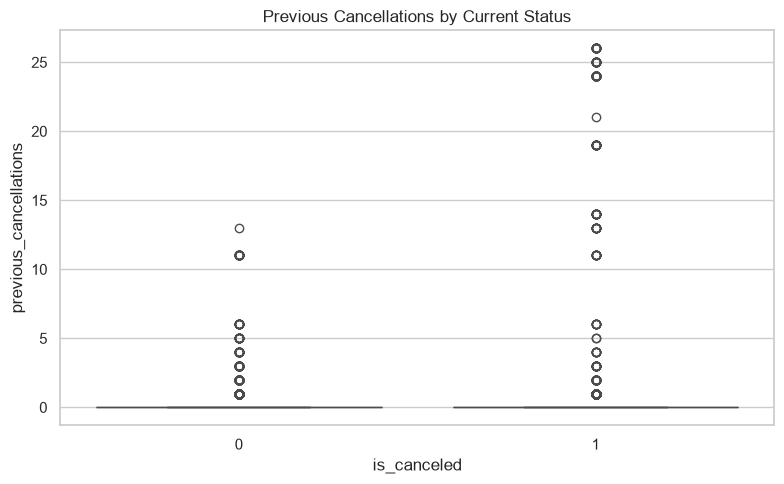

In [10]:
# ============================================================
# STEP 66 — PREVIOUS CANCELLATIONS BOXPLOT
# ============================================================

print("\n" + "=" * 70)
print("STEP 66 — PREVIOUS CANCELLATIONS")
print("=" * 70)

if "previous_cancellations" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=target_column,
        y="previous_cancellations"
    )

    plt.title("Previous Cancellations by Current Status")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            VISUALIZATION_FOLDER,
            "step_66_previous_cancellations.png"
        ),
        dpi=300
    )

    plt.show()


STEP 67 — TOTAL NIGHTS


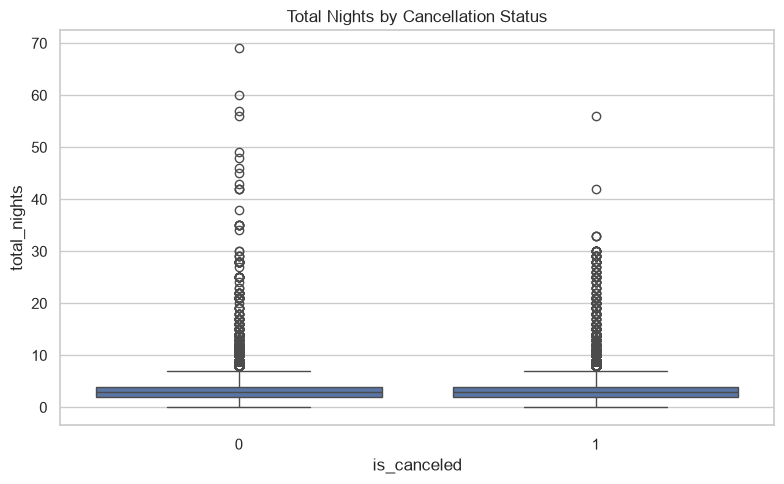

In [11]:
# ============================================================
# STEP 67 — TOTAL NIGHTS BOXPLOT
# ============================================================

print("\n" + "=" * 70)
print("STEP 67 — TOTAL NIGHTS")
print("=" * 70)

if "total_nights" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=target_column,
        y="total_nights"
    )

    plt.title("Total Nights by Cancellation Status")
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_67_total_nights.png"),
        dpi=300
    )

    plt.show()


STEP 68 — DISTRIBUTION CHANNEL


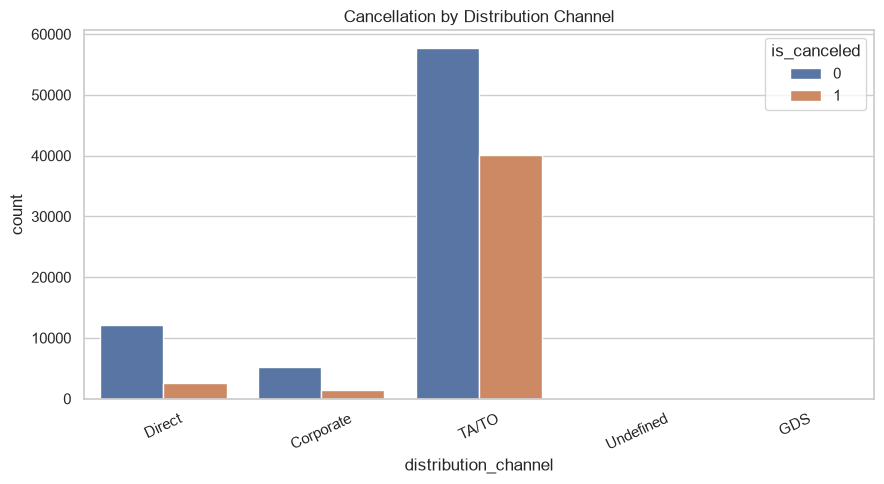

In [12]:
# ============================================================
# STEP 68 — CANCELLATION BY DISTRIBUTION CHANNEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 68 — DISTRIBUTION CHANNEL")
print("=" * 70)

if "distribution_channel" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="distribution_channel",
        hue=target_column
    )

    plt.title("Cancellation by Distribution Channel")
    plt.xticks(rotation=25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            VISUALIZATION_FOLDER,
            "step_68_distribution_channel.png"
        ),
        dpi=300
    )

    plt.show()


STEP 69 — MEAL TYPE


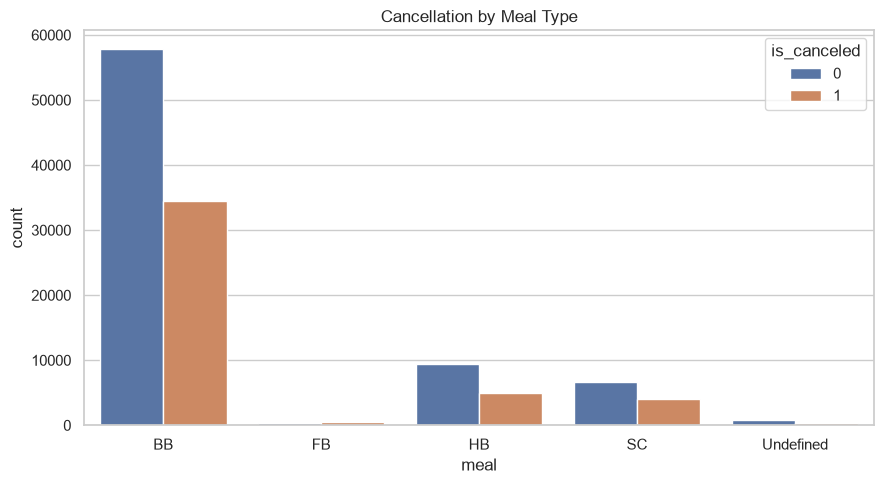

In [13]:
# ============================================================
# STEP 69 — CANCELLATION BY MEAL TYPE
# ============================================================

print("\n" + "=" * 70)
print("STEP 69 — MEAL TYPE")
print("=" * 70)

if "meal" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="meal",
        hue=target_column
    )

    plt.title("Cancellation by Meal Type")
    plt.tight_layout()

    plt.savefig(
        os.path.join(VISUALIZATION_FOLDER, "step_69_meal_type.png"),
        dpi=300
    )

    plt.show()

In [14]:
# ============================================================
# STEP 70 — SAVE VISUALIZATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 70 — VISUALIZATION SUMMARY")
print("=" * 70)

visualization_files = sorted(
    os.listdir(VISUALIZATION_FOLDER)
)

for file in visualization_files:
    print(file)

with open(
    os.path.join(VISUALIZATION_FOLDER, "step_70_visualization_summary.txt"),
    "w",
    encoding="utf-8"
) as file:

    file.write("HOTEL BOOKING VISUALIZATION SUMMARY\n\n")

    for filename in visualization_files:
        file.write(filename + "\n")

print("\nMEMBER 4 — STEPS 57–70 COMPLETED")


STEP 70 — VISUALIZATION SUMMARY
step_57_cancellation_count.png
step_58_hotel_type.png
step_59_lead_time.png
step_60_adr_boxplot.png
step_61_monthly_rate.png
step_62_customer_type.png
step_63_deposit_type.png
step_64_market_segment.png
step_65_correlation_heatmap.png
step_66_previous_cancellations.png
step_67_total_nights.png
step_68_distribution_channel.png
step_69_meal_type.png

MEMBER 4 — STEPS 57–70 COMPLETED
